# Data Analysis Assignment (EDA + Data Cleaning)

Datasets: 1) Loan  2) Adult  3) Hotel Booking

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Dataset 1: Loan Dataset

## Load data

In [2]:
df = pd.read_csv("loan-train.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.shape

(1614, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 221.3 KB


In [5]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,1614.000000,1614.000000,1592.000000,1600.000000,1564.00000
mean,8746.304833,3658.722999,218.846734,290.475000,0.63555
std,6249.885122,3291.745935,133.623293,81.899735,0.48143
min,150.000000,0.000000,9.000000,12.000000,0.00000
25%,3675.250000,986.250000,112.000000,240.000000,0.00000
50%,7045.000000,2941.500000,180.000000,360.000000,1.00000
75%,13251.000000,5893.000000,324.000000,360.000000,1.00000
max,81000.000000,41667.000000,700.000000,480.000000,1.00000


## Missing values and duplicates

In [6]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [7]:
print("duplicate rows:", df.duplicated().sum())
print("unique Loan_ID:", df["Loan_ID"].nunique(), "out of", len(df))

duplicate rows: 0
unique Loan_ID: 1538 out of 1614


In [8]:
df[df["Loan_ID"].duplicated(keep=False)].sort_values("Loan_ID").head(6)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
614,LP003002,Male,Yes,0,Not Graduate,Yes,8295,6148.0,330.0,360.0,0.0,Urban,Y
615,LP003002,Female,Yes,2,Graduate,No,13525,6635.0,217.0,180.0,0.0,Urban,Y
618,LP003029,Female,Yes,0,Graduate,Yes,17556,9346.0,298.0,180.0,0.0,Semiurban,Y
619,LP003029,Male,Yes,0,Graduate,Yes,6451,3274.0,353.0,240.0,1.0,Semiurban,N
631,LP003103,Male,No,2,Not Graduate,No,9952,8631.0,458.0,360.0,1.0,Urban,Y
632,LP003103,Female,No,2,Not Graduate,Yes,15868,5843.0,245.0,180.0,0.0,Urban,Y


## Univariate analysis

### Loan_ID

In [10]:
print(df["Loan_ID"].head())
print("It is only an ID column, no plot needed")

0    LP001002
1    LP001003
2    LP001005
3    LP001006
4    LP001008
Name: Loan_ID, dtype: str
It is only an ID column, no plot needed


### Categorical columns

Gender
Male      980
Female    621
NaN        13
Name: count, dtype: int64


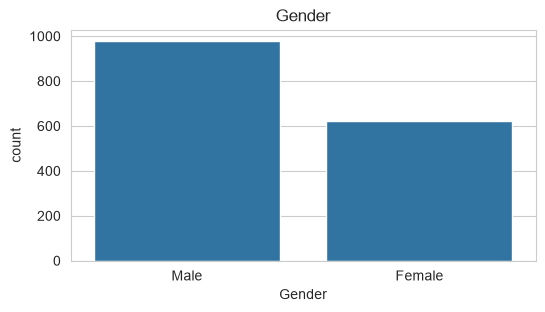

Married
Yes    925
No     686
NaN      3
Name: count, dtype: int64


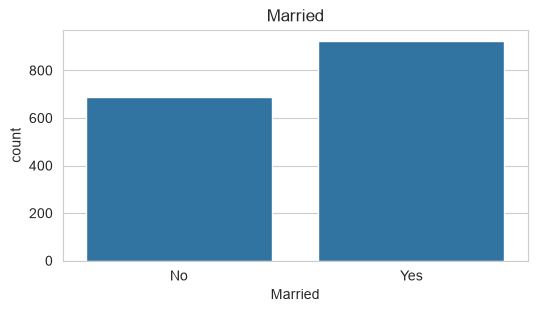

Dependents
0      619
1      341
2      336
3+     303
NaN     15
Name: count, dtype: int64


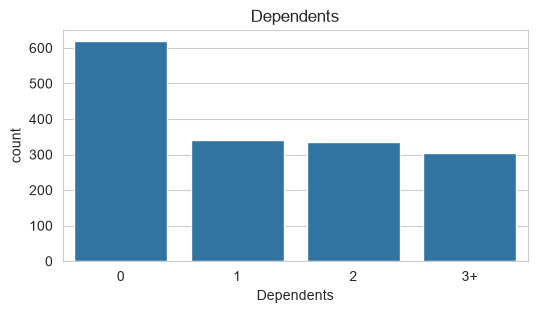

Education
Graduate        952
Not Graduate    662
Name: count, dtype: int64


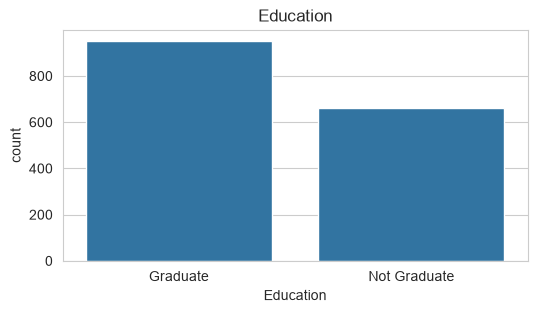

Self_Employed
No     999
Yes    583
NaN     32
Name: count, dtype: int64


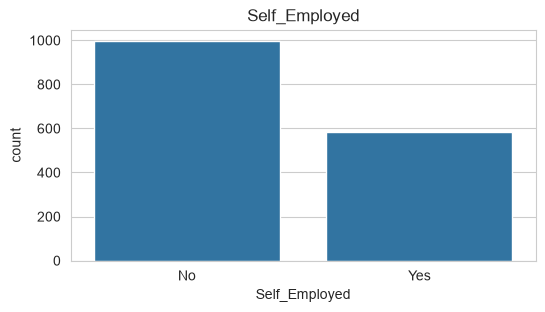

Credit_History
1.0    994
0.0    570
NaN     50
Name: count, dtype: int64


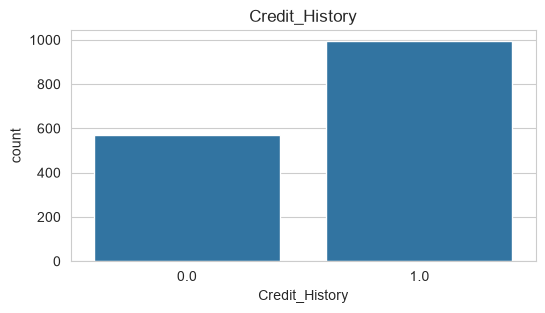

Loan_Amount_Term
360.0    845
180.0    384
240.0    331
480.0     15
NaN       14
300.0     13
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64


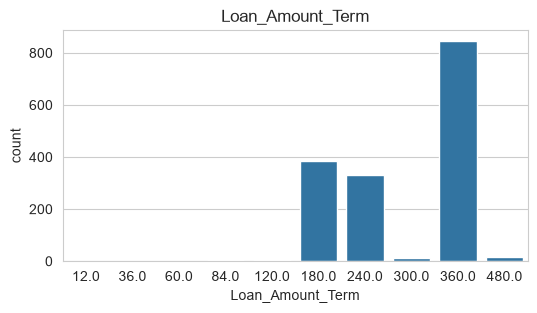

Property_Area
Urban        549
Semiurban    545
Rural        520
Name: count, dtype: int64


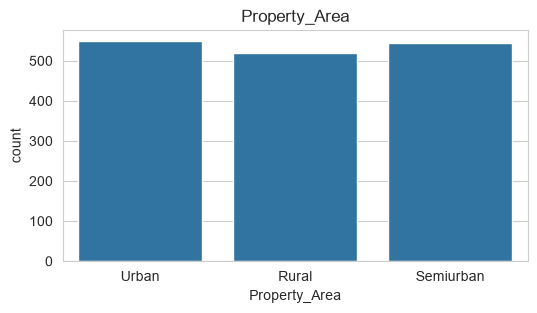

Loan_Status
Y    915
N    699
Name: count, dtype: int64


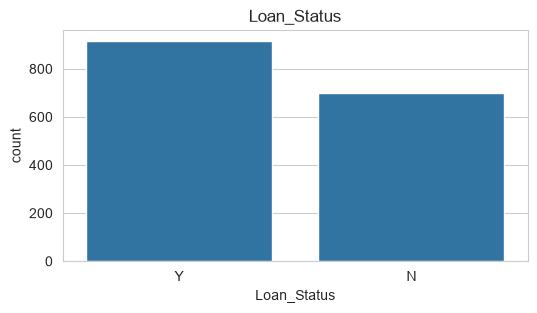

In [11]:
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed",
            "Credit_History", "Loan_Amount_Term", "Property_Area", "Loan_Status"]
for col in cat_cols:
    print(df[col].value_counts(dropna=False))
    plt.figure(figsize=(6, 3))
    sns.countplot(x=df[col])
    plt.title(col)
    plt.show()

### Numerical columns

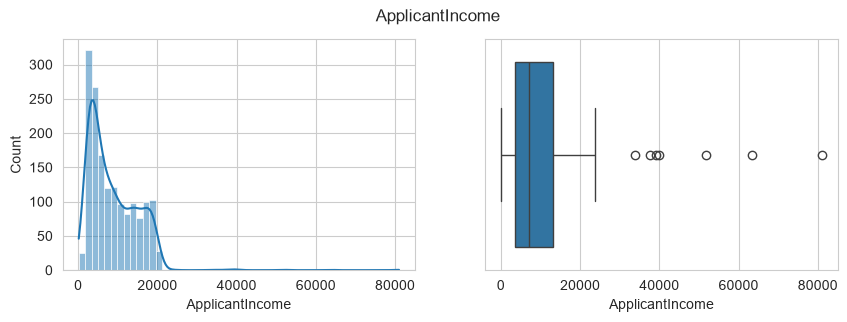

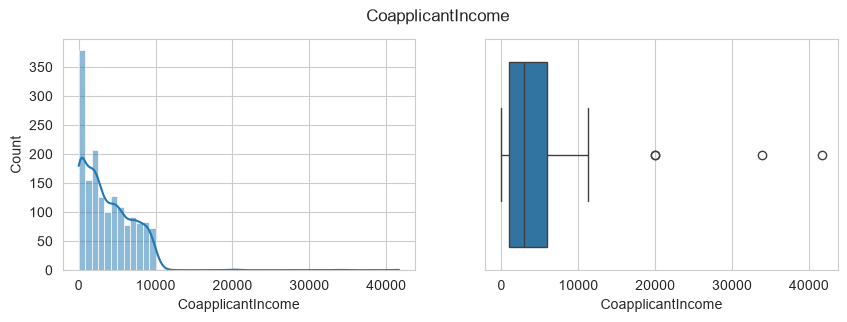

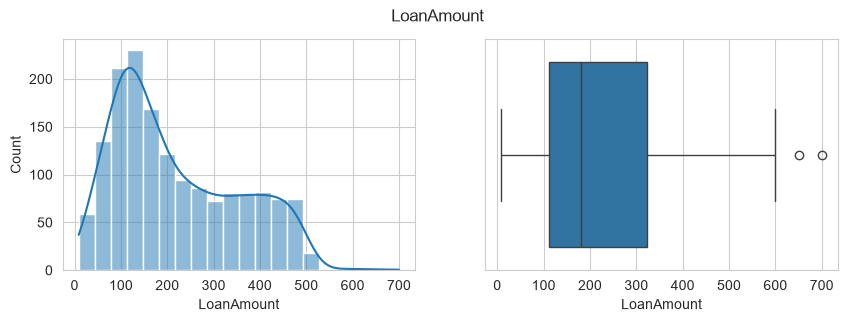

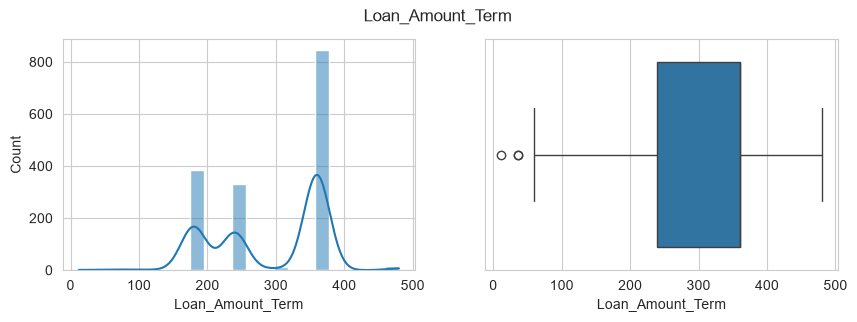

In [12]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df[col], kde=True, ax=ax[0])
    sns.boxplot(x=df[col], ax=ax[1])
    fig.suptitle(col)
    plt.show()

## Data cleaning

### Missing values

In [15]:
for col in ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History", "Loan_Amount_Term"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())

In [16]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

### Dependents has '3+', convert it to number

In [17]:
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(int)
df["Dependents"].value_counts()

Dependents
0    634
1    341
2    336
3    303
Name: count, dtype: int64

### Outliers (IQR method)

In [18]:
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    print(col, "outliers:", ((df[col] < low) | (df[col] > high)).sum())
    df[col] = df[col].clip(low, high)

ApplicantIncome outliers: 7
CoapplicantIncome outliers: 4
LoanAmount outliers: 2


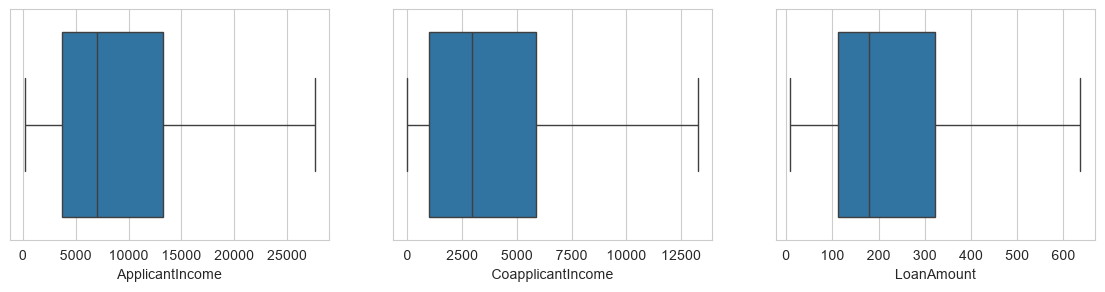

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for i, col in enumerate(["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    sns.boxplot(x=df[col], ax=ax[i])
plt.show()

## Bivariate analysis with Loan_Status

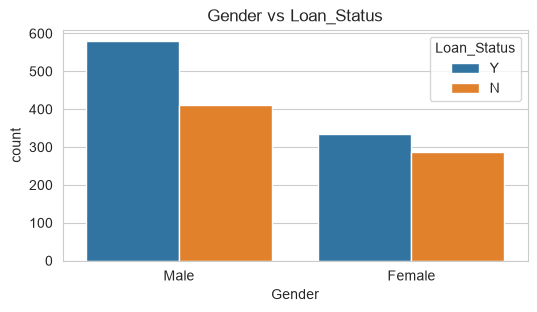

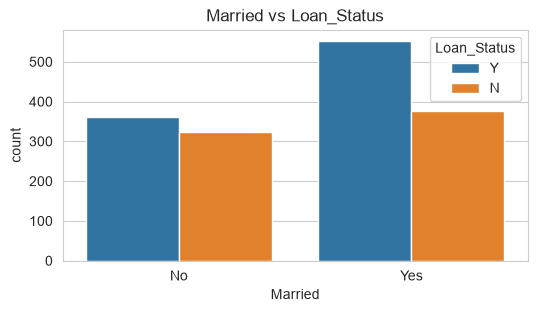

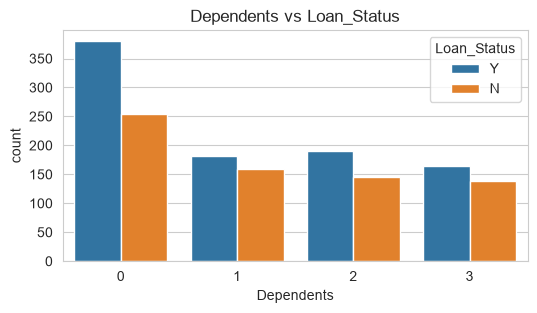

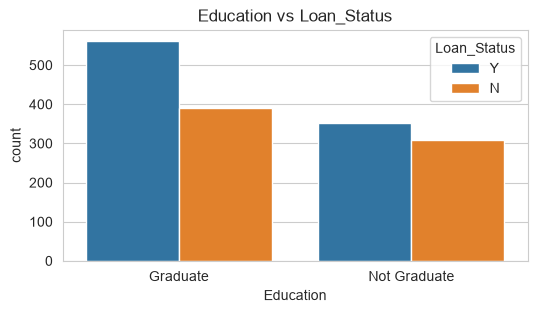

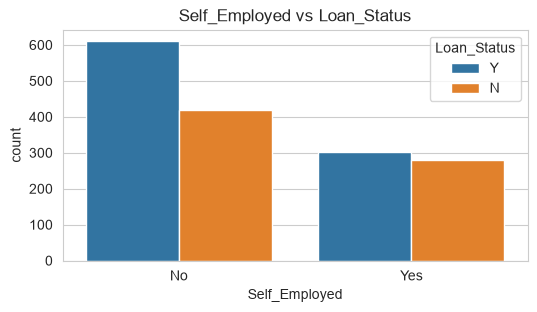

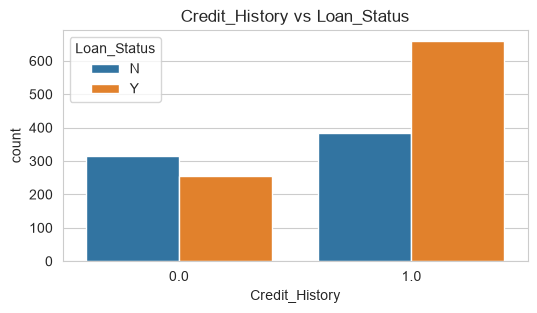

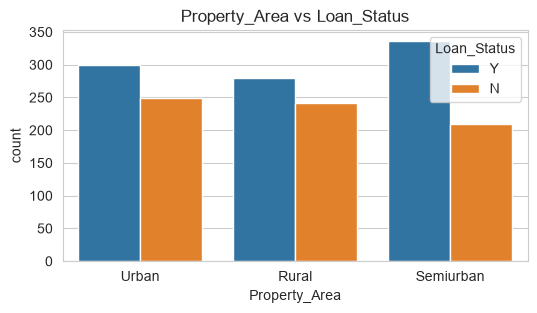

In [20]:
for col in ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Credit_History", "Property_Area"]:
    plt.figure(figsize=(6, 3))
    sns.countplot(x=df[col], hue=df["Loan_Status"])
    plt.title(col + " vs Loan_Status")
    plt.show()

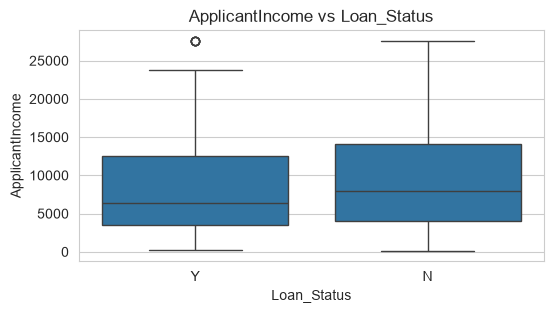

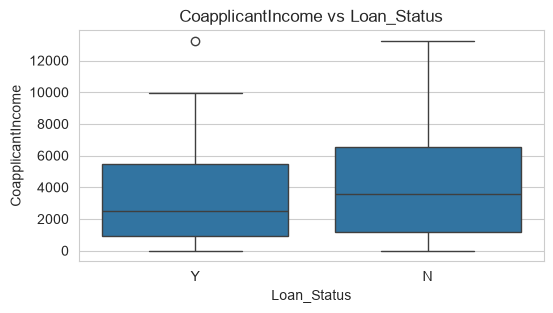

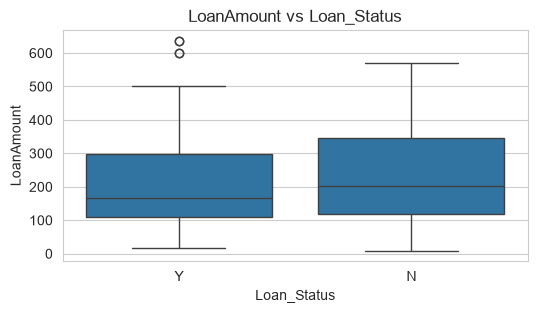

In [21]:
for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df["Loan_Status"], y=df[col])
    plt.title(col + " vs Loan_Status")
    plt.show()

### Correlation

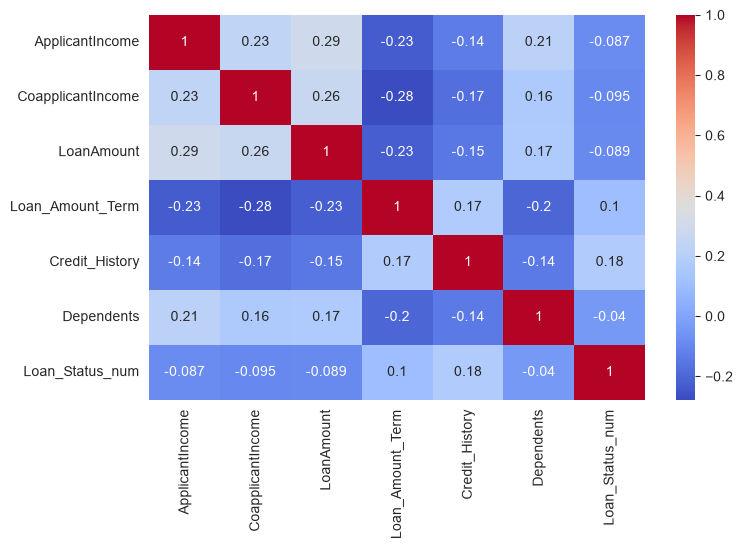

In [22]:
df["Loan_Status_num"] = df["Loan_Status"].map({"Y": 1, "N": 0})
plt.figure(figsize=(8, 5))
sns.heatmap(df[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term",
                "Credit_History", "Dependents", "Loan_Status_num"]].corr(), annot=True, cmap="coolwarm")
plt.show()

In [23]:
df.to_csv("loan_cleaned.csv", index=False)

# Dataset 2: Adult Dataset

## Load data

In [24]:
df = pd.read_csv("adult.csv")
df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [25]:
df.shape

(48842, 15)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [ ]:
df.describe()

## Missing values and duplicates

In [27]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [28]:
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(col, (df[col] == "?").sum())

workclass 2799
education 0
marital-status 0
occupation 2809
relationship 0
race 0
gender 0
native-country 857
income 0


In [29]:
print("duplicate rows:", df.duplicated().sum())

duplicate rows: 52


## Univariate analysis

### Categorical columns

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
?                    2799
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64


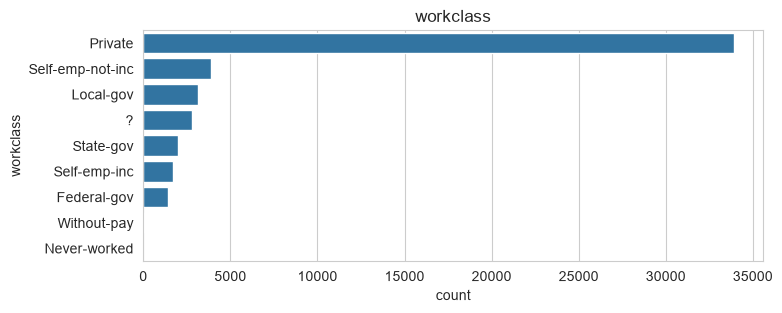

education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, dtype: int64


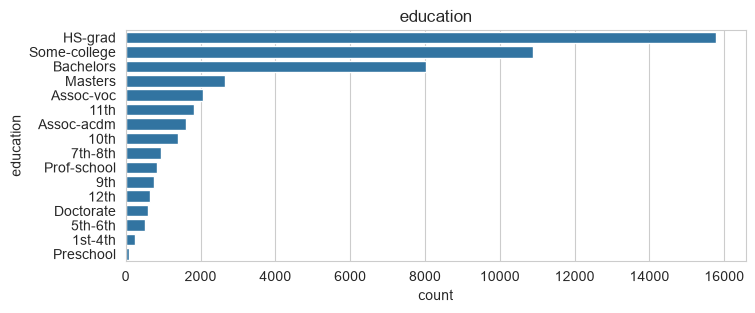

marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37
Name: count, dtype: int64


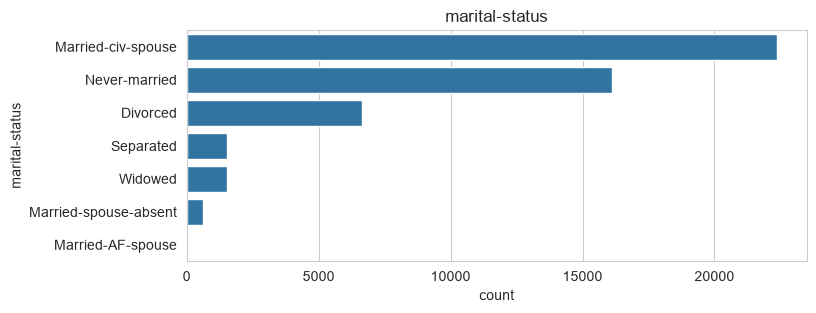

occupation
Prof-specialty       6172
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales                5504
Other-service        4923
Machine-op-inspct    3022
?                    2809
Transport-moving     2355
Handlers-cleaners    2072
Farming-fishing      1490
Tech-support         1446
Protective-serv       983
Priv-house-serv       242
Armed-Forces           15
Name: count, dtype: int64


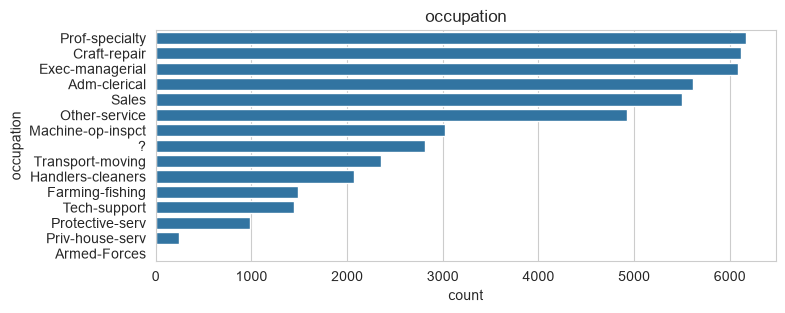

relationship
Husband           19716
Not-in-family     12583
Own-child          7581
Unmarried          5125
Wife               2331
Other-relative     1506
Name: count, dtype: int64


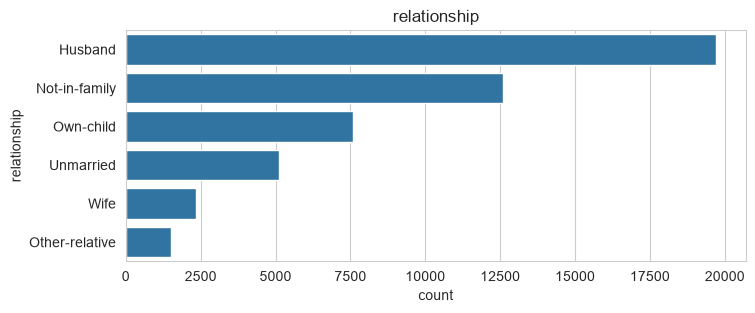

race
White                 41762
Black                  4685
Asian-Pac-Islander     1519
Amer-Indian-Eskimo      470
Other                   406
Name: count, dtype: int64


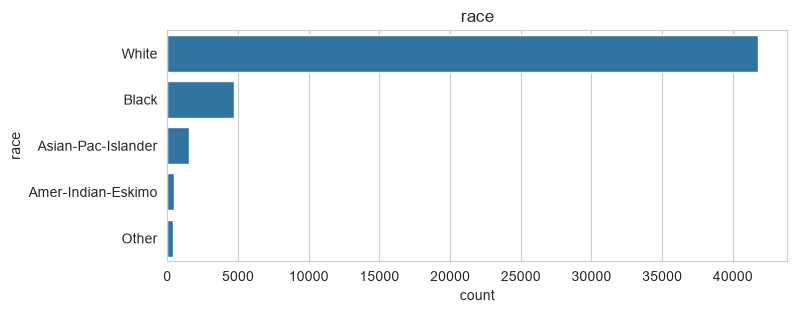

gender
Male      32650
Female    16192
Name: count, dtype: int64


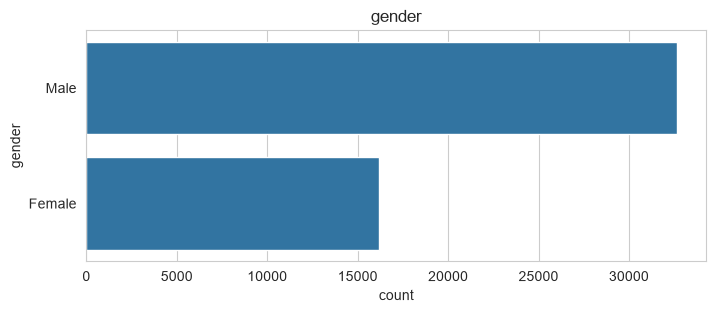

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


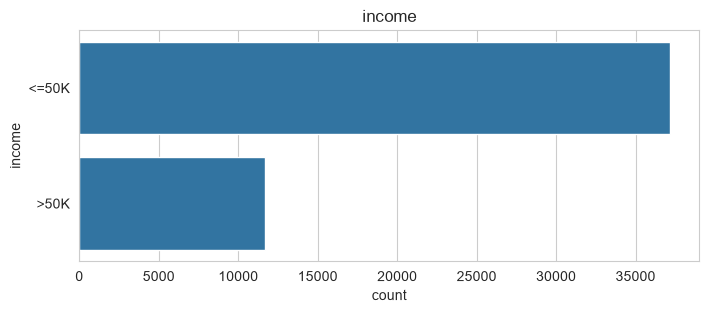

In [30]:
cat_cols = ["workclass", "education", "marital-status", "occupation", "relationship",
            "race", "gender", "income"]
for col in cat_cols:
    print(df[col].value_counts())
    plt.figure(figsize=(8, 3))
    sns.countplot(y=df[col], order=df[col].value_counts().index)
    plt.title(col)
    plt.show()

native-country
United-States    43832
Mexico             951
?                  857
Philippines        295
Germany            206
Puerto-Rico        184
Canada             182
El-Salvador        155
India              151
Cuba               138
Name: count, dtype: int64


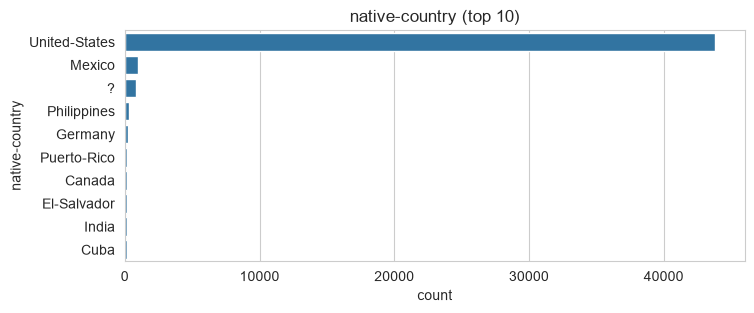

In [31]:
print(df["native-country"].value_counts().head(10))
plt.figure(figsize=(8, 3))
sns.countplot(y=df["native-country"], order=df["native-country"].value_counts().head(10).index)
plt.title("native-country (top 10)")
plt.show()

### Numerical columns

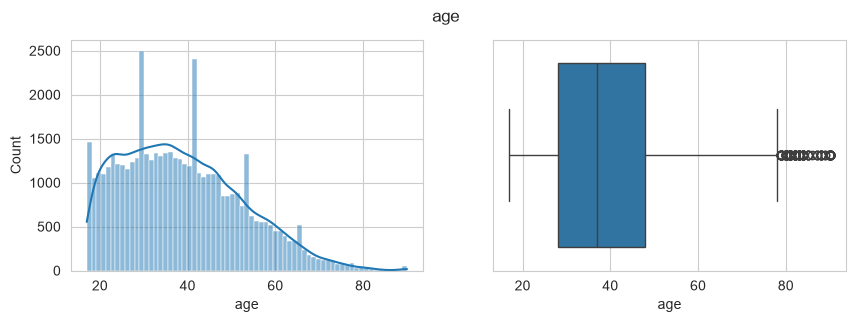

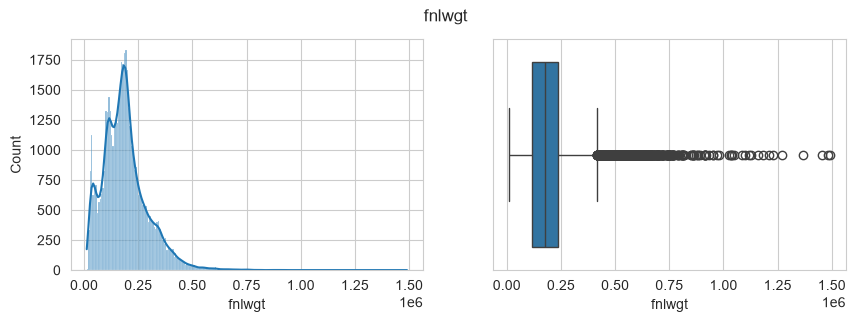

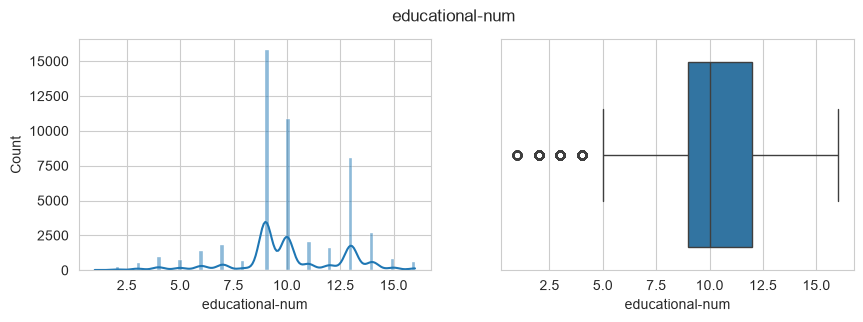

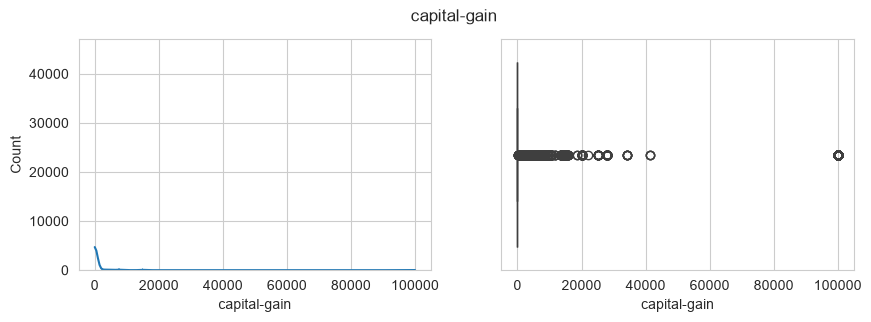

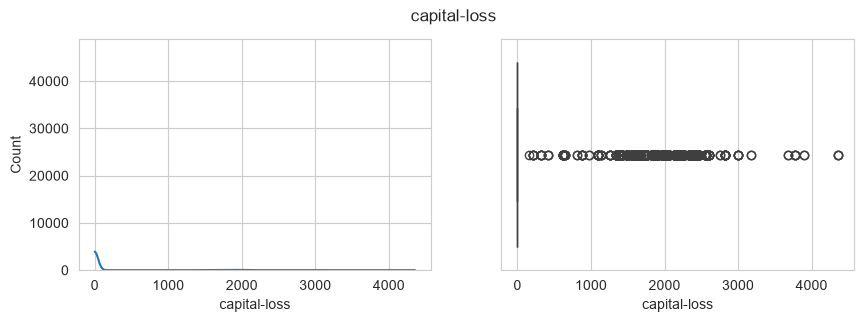

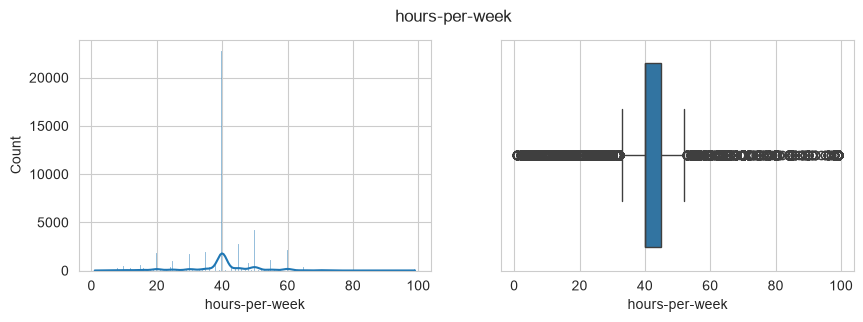

In [32]:
num_cols = ["age", "fnlwgt", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df[col], kde=True, ax=ax[0])
    sns.boxplot(x=df[col], ax=ax[1])
    fig.suptitle(col)
    plt.show()

## Data cleaning

### Replace '?' with NaN and fill missing values

In [33]:
df = df.replace("?", np.nan)
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

In [34]:
for col in ["workclass", "occupation", "native-country"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df.isnull().sum().sum()

np.int64(0)

### Duplicates

In [35]:
df = df.drop_duplicates()
print(df.shape)

(48789, 15)


### Outliers (IQR method)

In [36]:
for col in ["age", "fnlwgt", "hours-per-week"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    print(col, "outliers:", ((df[col] < low) | (df[col] > high)).sum())
    df[col] = df[col].clip(low, high)

age outliers: 215
fnlwgt outliers: 1453
hours-per-week outliers: 13486


In [37]:
print((df["capital-gain"] == 0).mean())
print((df["capital-loss"] == 0).mean())

0.9172969316854209
0.9532271618602554


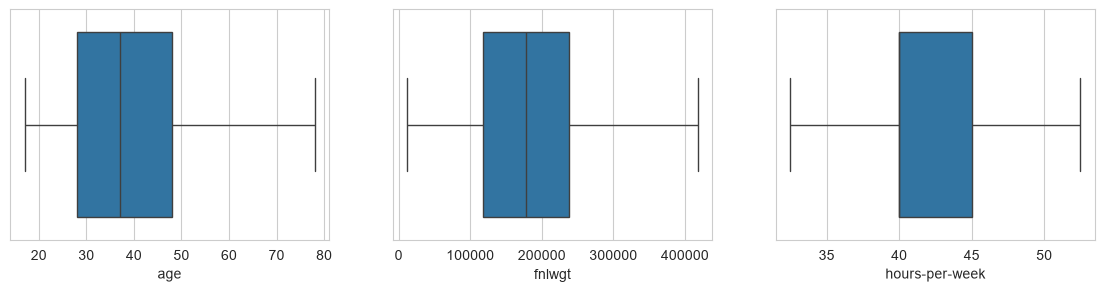

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for i, col in enumerate(["age", "fnlwgt", "hours-per-week"]):
    sns.boxplot(x=df[col], ax=ax[i])
plt.show()

### education and educational-num are the same information

In [39]:
df.groupby("education")["educational-num"].nunique().max()

np.int64(1)

## Bivariate analysis with income

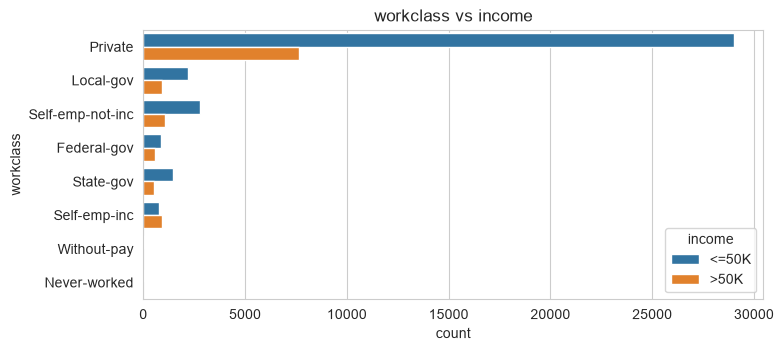

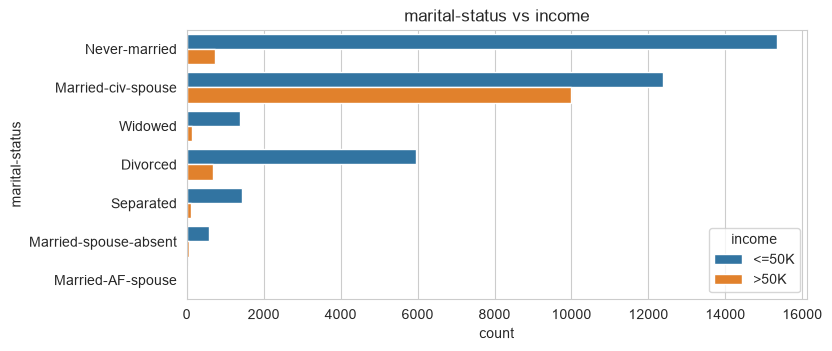

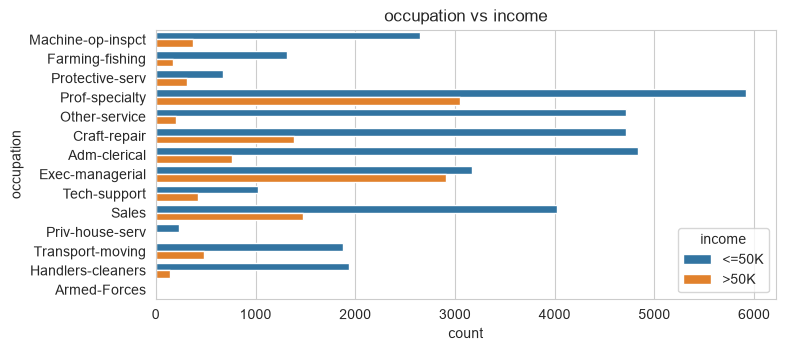

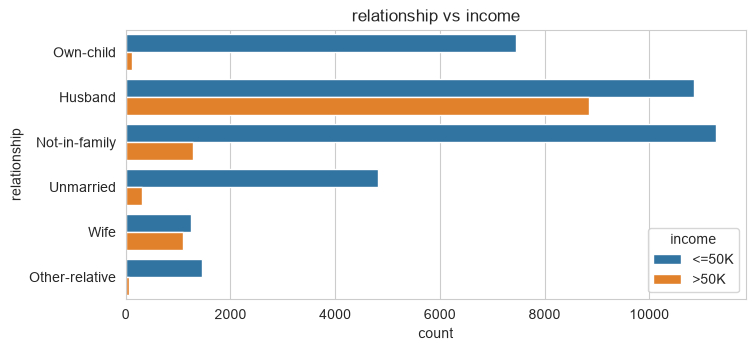

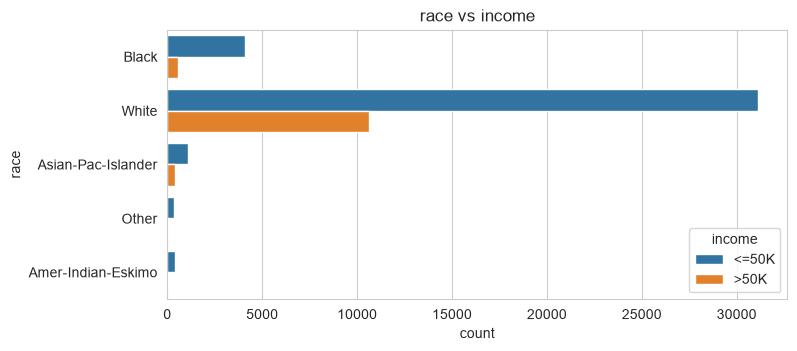

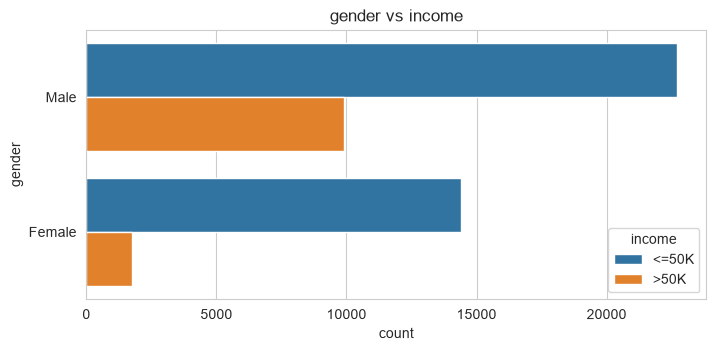

In [40]:
for col in ["workclass", "marital-status", "occupation", "relationship", "race", "gender"]:
    plt.figure(figsize=(8, 3.5))
    sns.countplot(y=df[col], hue=df["income"])
    plt.title(col + " vs income")
    plt.show()

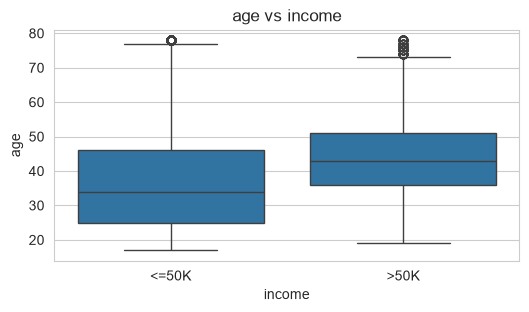

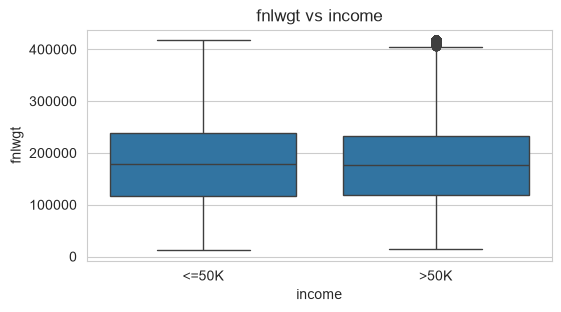

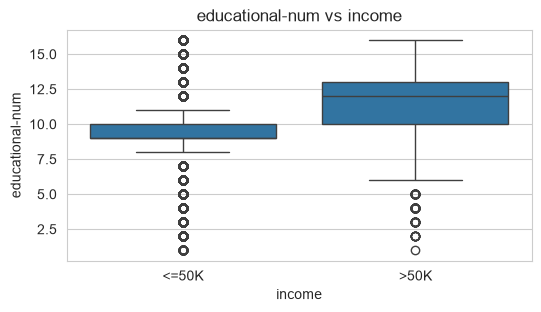

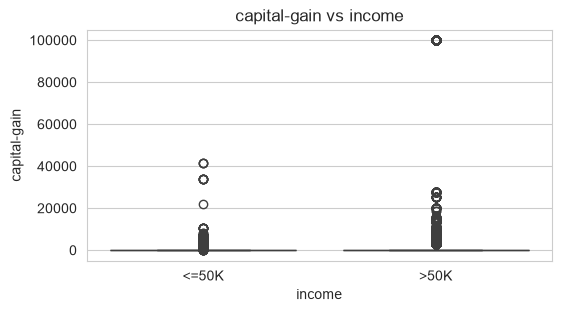

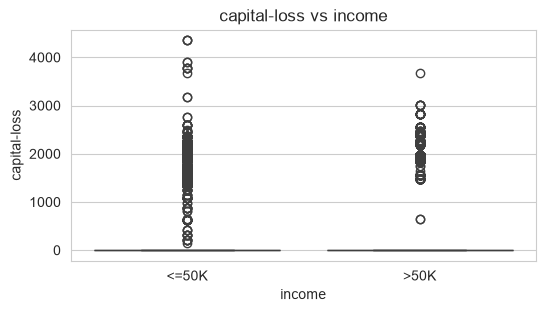

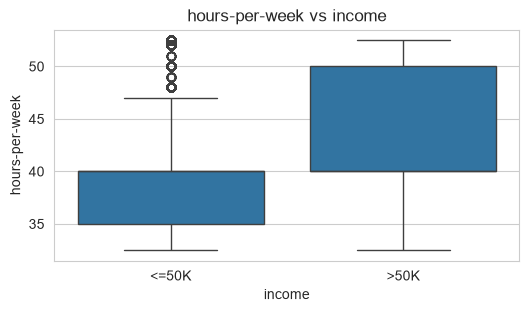

In [41]:
for col in ["age", "fnlwgt", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df["income"], y=df[col])
    plt.title(col + " vs income")
    plt.show()

### Correlation

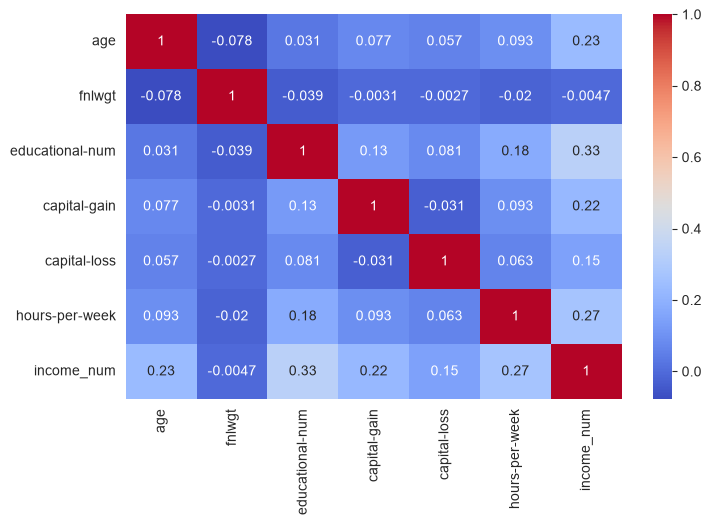

In [42]:
df["income_num"] = df["income"].map({"<=50K": 0, ">50K": 1})
plt.figure(figsize=(8, 5))
sns.heatmap(df[["age", "fnlwgt", "educational-num", "capital-gain", "capital-loss",
                "hours-per-week", "income_num"]].corr(), annot=True, cmap="coolwarm")
plt.show()

In [43]:
df.to_csv("adult_cleaned.csv", index=False)

# Dataset 3: Hotel Booking Dataset

## Load data

In [44]:
df = pd.read_csv("hotel_booking.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


In [45]:
df.shape

(119390, 36)

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [47]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Missing values and duplicates

In [48]:
m = df.isnull().sum()
m[m > 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

In [49]:
print("company missing %:", round(df["company"].isnull().mean() * 100, 1))

company missing %: 94.3


In [50]:
pii = ["name", "email", "phone-number", "credit_card"]
print("duplicate rows:", df.duplicated().sum())
print("duplicate rows without personal columns:", df.drop(columns=pii).duplicated().sum())

duplicate rows: 0
duplicate rows without personal columns: 31994


## Univariate analysis

### Categorical columns

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


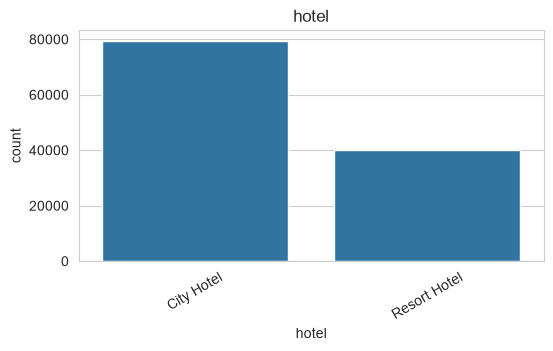

is_canceled
0    75166
1    44224
Name: count, dtype: int64


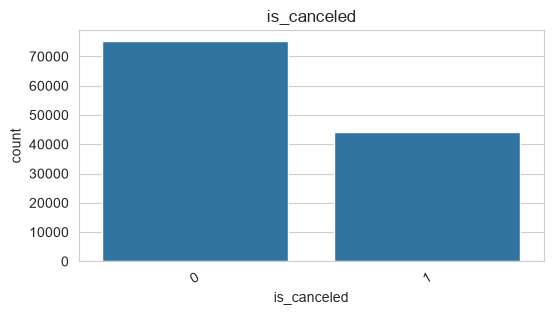

arrival_date_year
2016    56707
2017    40687
2015    21996
Name: count, dtype: int64


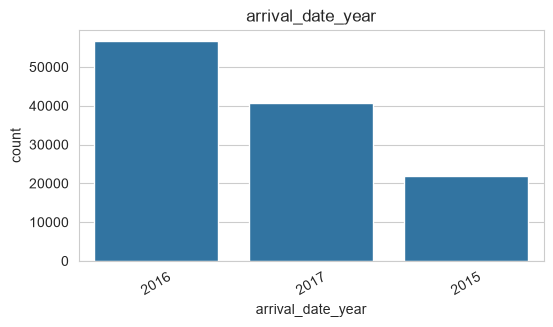

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64


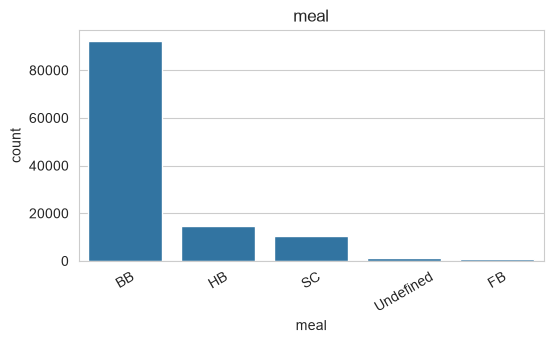

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64


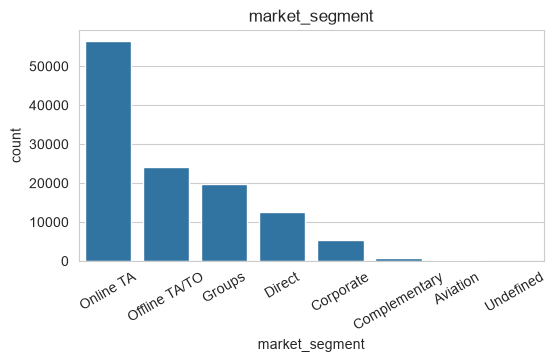

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64


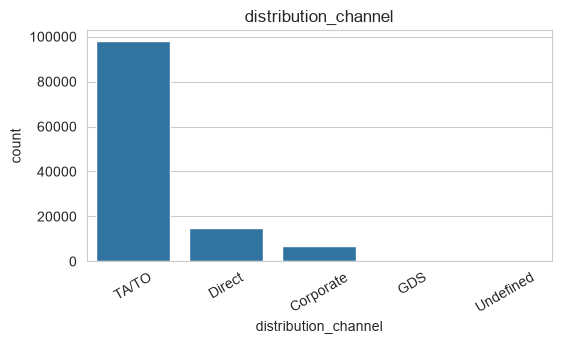

is_repeated_guest
0    115580
1      3810
Name: count, dtype: int64


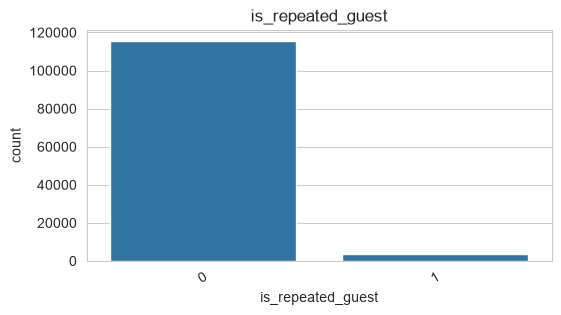

reserved_room_type
A    85994
D    19201
E     6535
F     2897
G     2094
B     1118
C      932
H      601
P       12
L        6
Name: count, dtype: int64


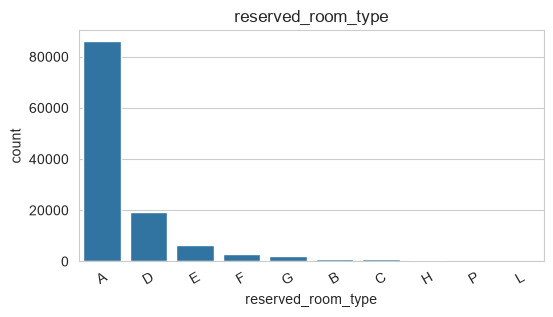

assigned_room_type
A    74053
D    25322
E     7806
F     3751
G     2553
C     2375
B     2163
H      712
I      363
K      279
P       12
L        1
Name: count, dtype: int64


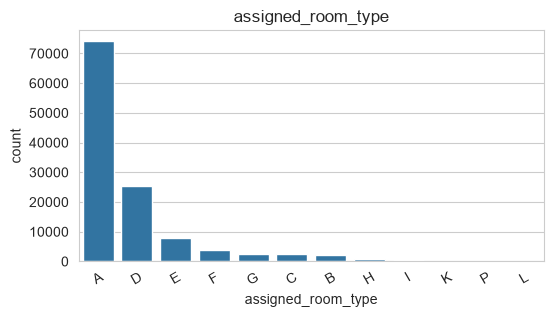

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64


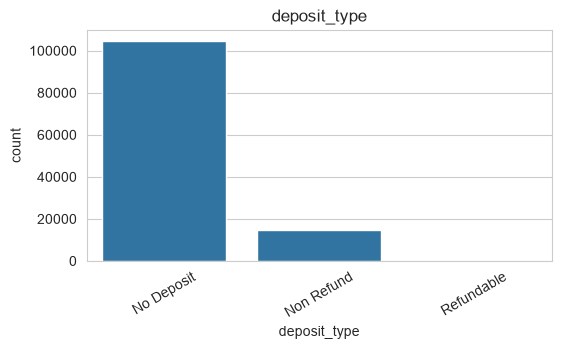

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64


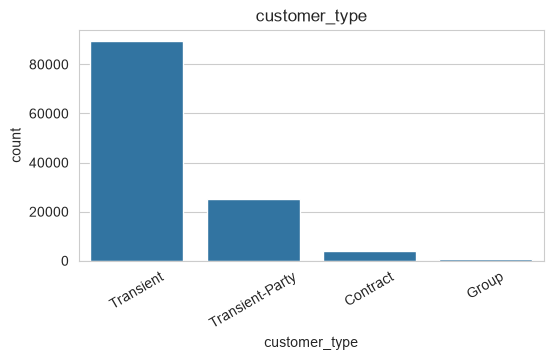

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64


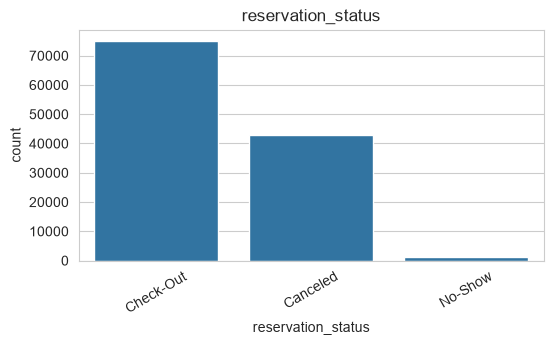

In [51]:
cat_cols = ["hotel", "is_canceled", "arrival_date_year", "meal", "market_segment",
            "distribution_channel", "is_repeated_guest", "reserved_room_type",
            "assigned_room_type", "deposit_type", "customer_type", "reservation_status"]
for col in cat_cols:
    print(df[col].value_counts())
    plt.figure(figsize=(6, 3))
    sns.countplot(x=df[col], order=df[col].value_counts().index)
    plt.xticks(rotation=30)
    plt.title(col)
    plt.show()

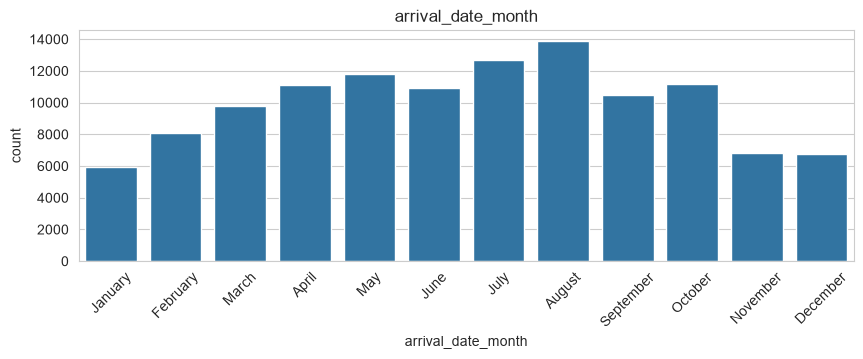

In [52]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
plt.figure(figsize=(10, 3))
sns.countplot(x=df["arrival_date_month"], order=month_order)
plt.xticks(rotation=45)
plt.title("arrival_date_month")
plt.show()

country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64


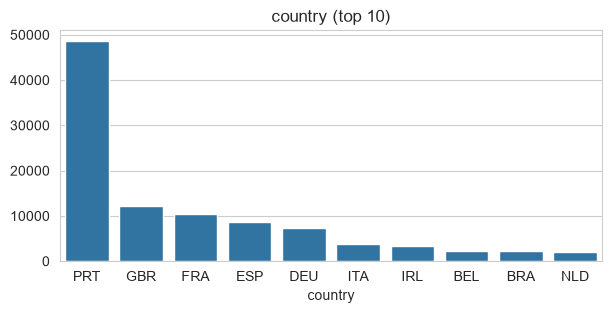

agent
9.0      31961
240.0    13922
1.0       7191
14.0      3640
7.0       3539
6.0       3290
250.0     2870
241.0     1721
28.0      1666
8.0       1514
Name: count, dtype: int64


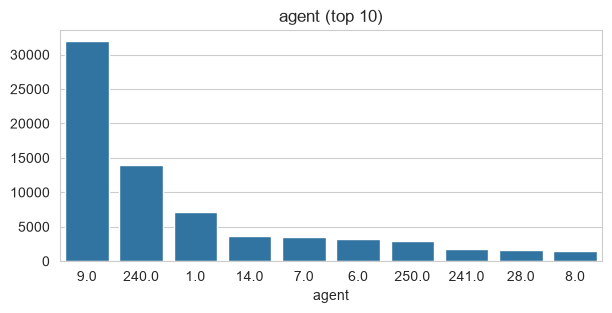

In [53]:
for col in ["country", "agent"]:
    top = df[col].value_counts().head(10)
    print(top)
    plt.figure(figsize=(7, 3))
    sns.barplot(x=top.index.astype(str), y=top.values)
    plt.title(col + " (top 10)")
    plt.show()

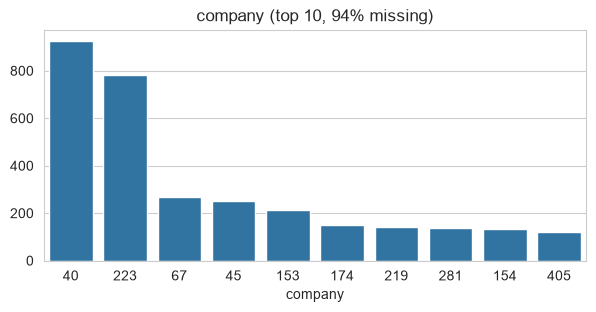

In [54]:
top = df["company"].value_counts().head(10)
plt.figure(figsize=(7, 3))
sns.barplot(x=top.index.astype(int).astype(str), y=top.values)
plt.title("company (top 10, 94% missing)")
plt.show()

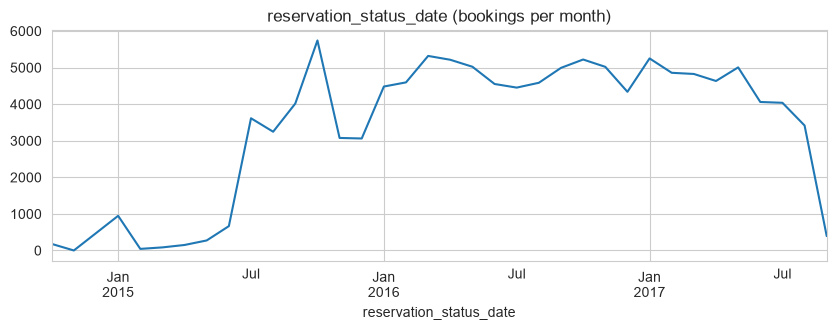

In [55]:
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])
df.groupby(df["reservation_status_date"].dt.to_period("M")).size().plot(figsize=(10, 3))
plt.title("reservation_status_date (bookings per month)")
plt.show()

### Numerical columns

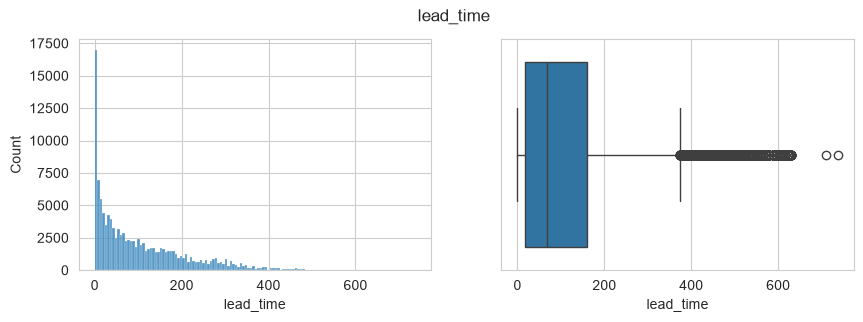

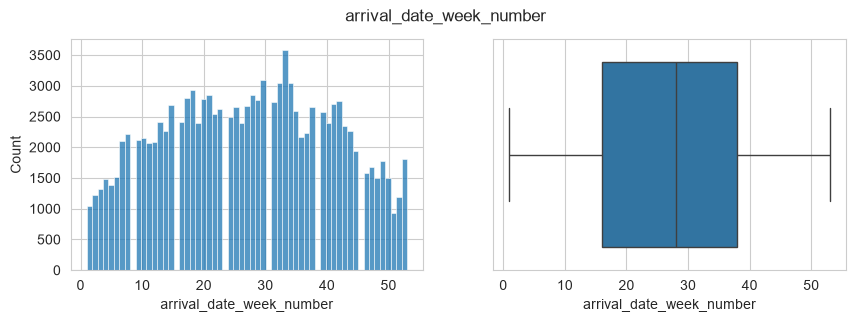

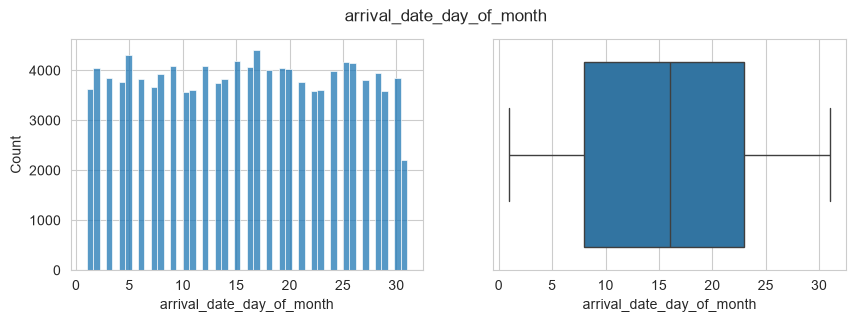

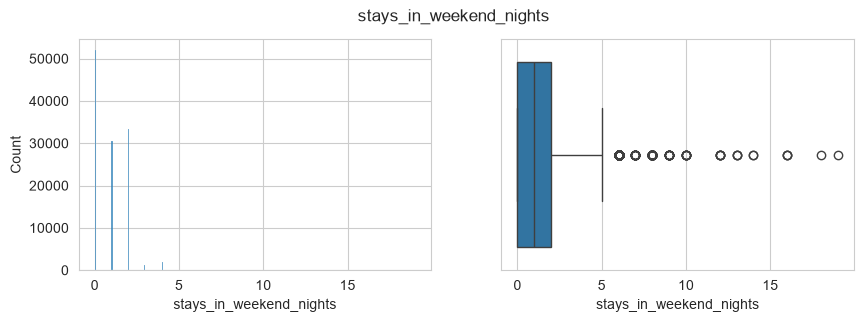

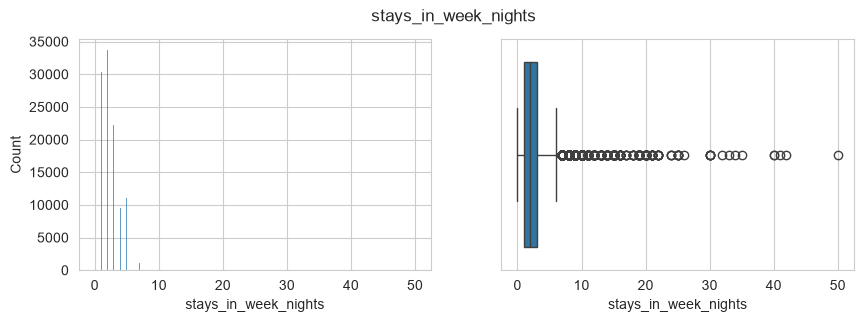

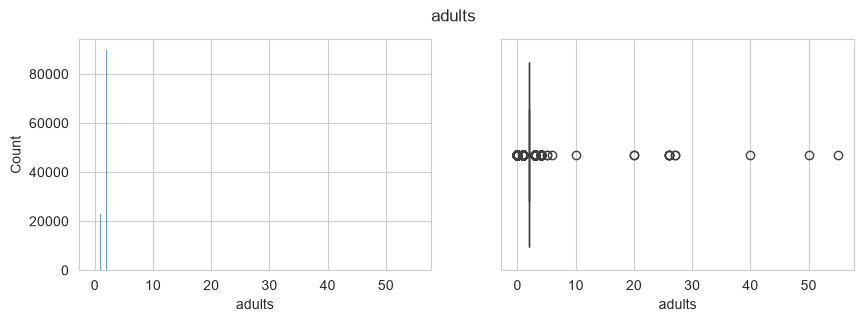

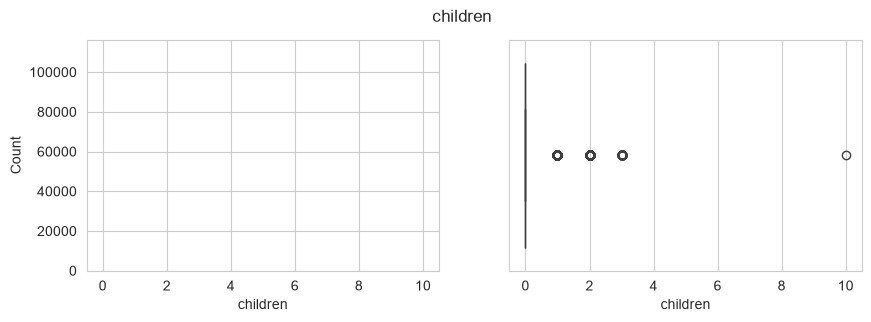

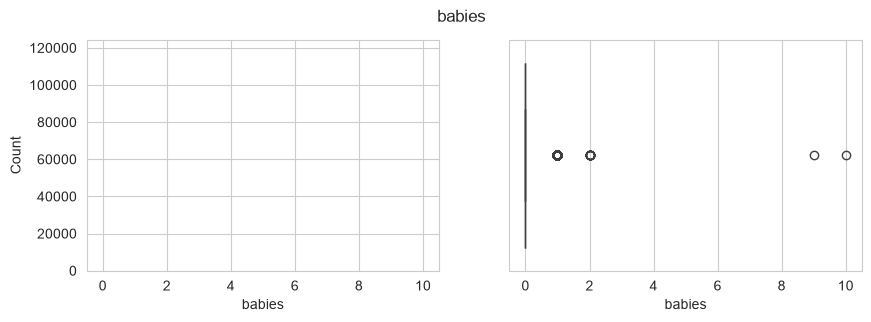

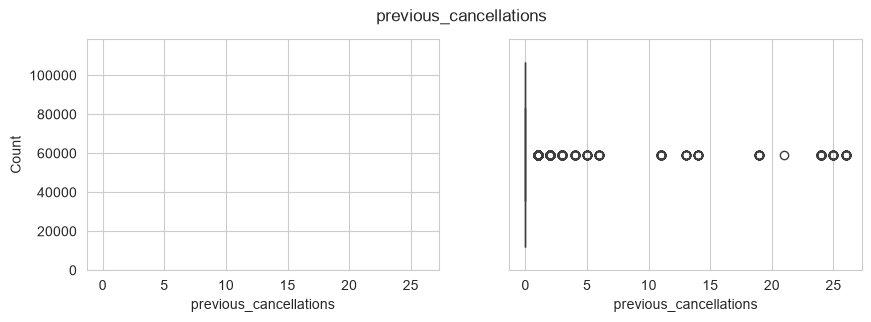

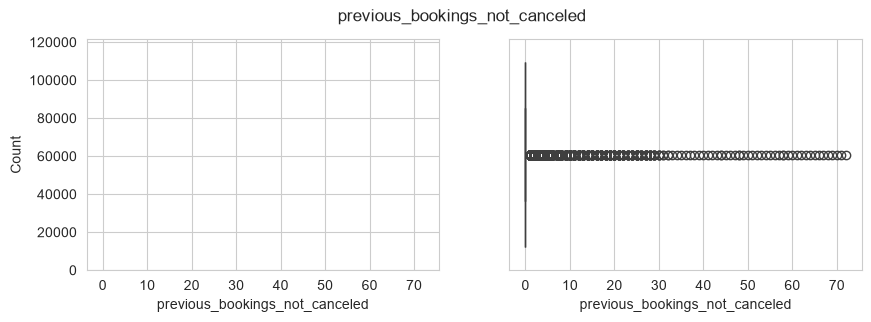

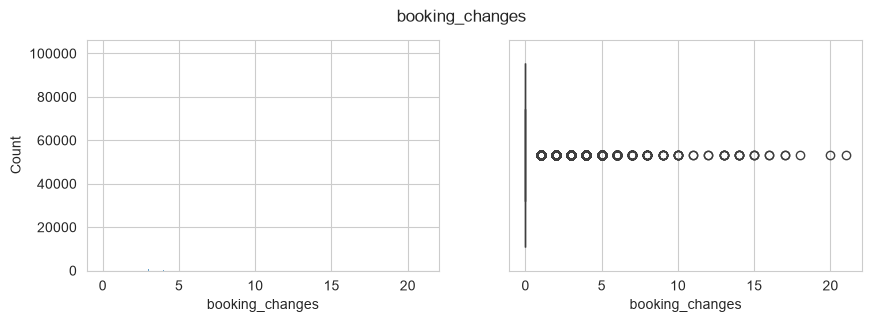

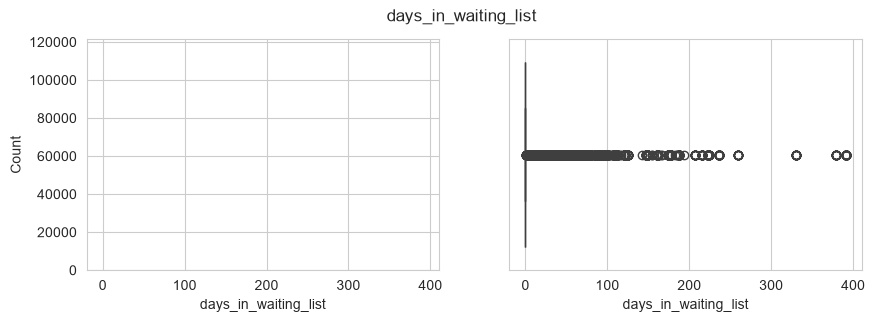

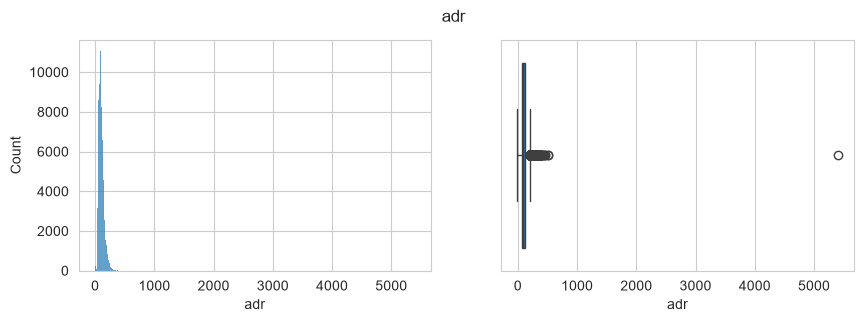

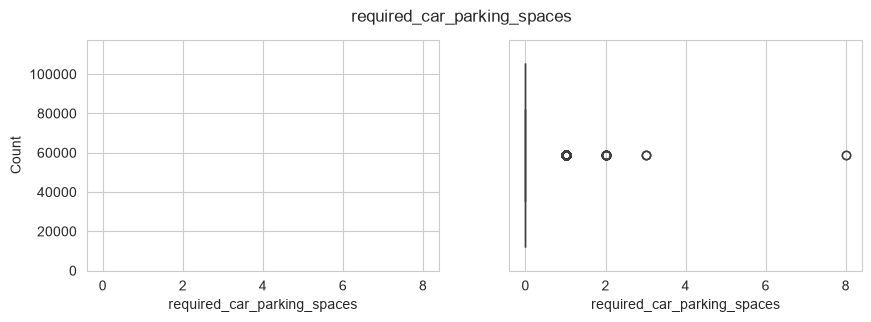

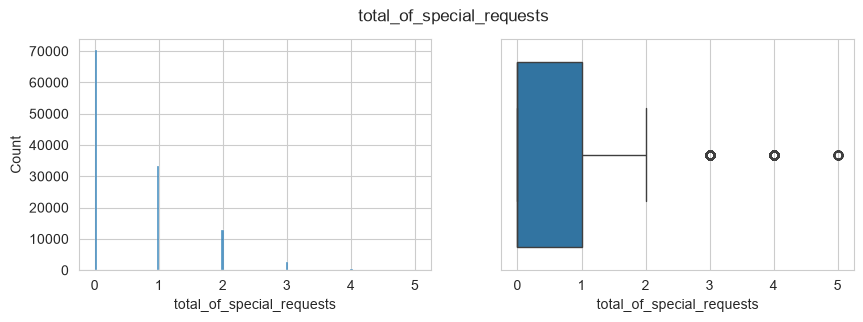

In [56]:
num_cols = ["lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
            "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
            "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "adr", "required_car_parking_spaces", "total_of_special_requests"]
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df[col].dropna(), kde=False, ax=ax[0])
    sns.boxplot(x=df[col], ax=ax[1])
    fig.suptitle(col)
    plt.show()

### Personal columns (name, email, phone-number, credit_card)

In [59]:
print("name unique:", df["name"].nunique())
print(df["name"].value_counts().head())
print()
print("phone unique:", df["phone-number"].nunique())
print("credit card unique:", df["credit_card"].nunique())
print(df["credit_card"].value_counts().head())

name unique: 81503
name
Michael Johnson      48
Robert Smith         48
Michael Smith        47
John Smith           46
Christopher Smith    44
Name: count, dtype: int64

phone unique: 119390
credit card unique: 9000
credit_card
************3627    28
************4923    28
************3793    27
************9864    27
************3972    27
Name: count, dtype: int64


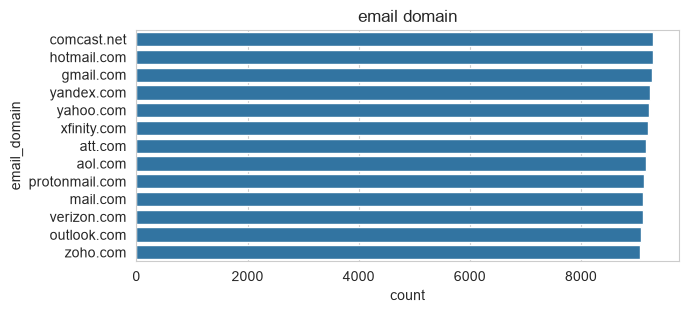

In [60]:
df["email_domain"] = df["email"].str.split("@").str[1]
plt.figure(figsize=(7, 3))
sns.countplot(y=df["email_domain"], order=df["email_domain"].value_counts().index)
plt.title("email domain")
plt.show()

## Data cleaning

### Duplicates

In [61]:
df = df.drop(columns=["email_domain"])
df = df.loc[df.drop(columns=pii).drop_duplicates().index]
print(df.shape)

(87396, 36)


### Missing values

In [62]:
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna(df["country"].mode()[0])
df["agent"] = df["agent"].fillna(0)      
df = df.drop(columns=["company"])       
df.isnull().sum().sum()

np.int64(0)

### 'Undefined' values

In [63]:
print((df["meal"] == "Undefined").sum())
df["meal"] = df["meal"].replace("Undefined", "SC")

492


### Wrong values

In [64]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

print("zero guests:", (df["total_guests"] == 0).sum())
print("zero nights:", (df["total_nights"] == 0).sum())
print("negative adr:", (df["adr"] < 0).sum())
print("adults > 10:", (df["adults"] > 10).sum())

zero guests: 166
zero nights: 651
negative adr: 1
adults > 10: 12


In [65]:
df = df[(df["total_guests"] > 0) & (df["total_nights"] > 0) & (df["adr"] >= 0) & (df["adults"] <= 10)]
print(df.shape)

(86626, 37)


### Outliers (IQR method)

In [66]:
for col in ["lead_time", "adr", "total_nights"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    high = q3 + 3 * iqr
    print(col, "outliers:", (df[col] > high).sum())
    df[col] = df[col].clip(upper=high)

lead_time outliers: 146
adr outliers: 136
total_nights outliers: 364


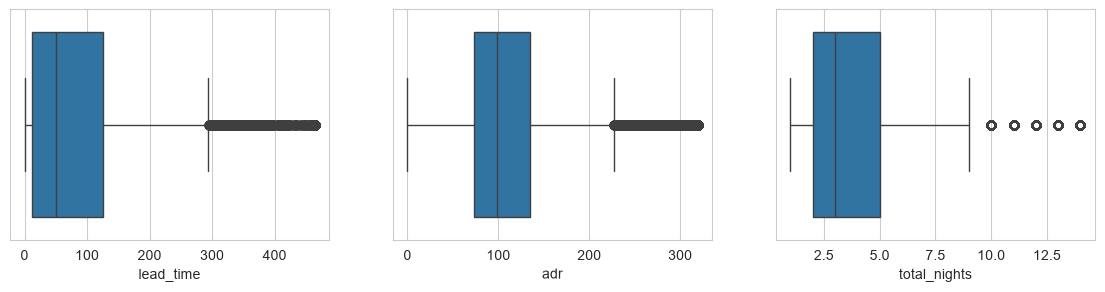

In [67]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for i, col in enumerate(["lead_time", "adr", "total_nights"]):
    sns.boxplot(x=df[col], ax=ax[i])
plt.show()

### Data types and personal columns

In [68]:
df["arrival_date"] = pd.to_datetime(df["arrival_date_year"].astype(str) + "-" +
                                    df["arrival_date_month"] + "-" +
                                    df["arrival_date_day_of_month"].astype(str))
df["agent"] = df["agent"].astype(int)
df = df.drop(columns=pii)    
df.info()

<class 'pandas.DataFrame'>
Index: 86626 entries, 2 to 119389
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           86626 non-null  str           
 1   is_canceled                     86626 non-null  int64         
 2   lead_time                       86626 non-null  int64         
 3   arrival_date_year               86626 non-null  int64         
 4   arrival_date_month              86626 non-null  str           
 5   arrival_date_week_number        86626 non-null  int64         
 6   arrival_date_day_of_month       86626 non-null  int64         
 7   stays_in_weekend_nights         86626 non-null  int64         
 8   stays_in_week_nights            86626 non-null  int64         
 9   adults                          86626 non-null  int64         
 10  children                        86626 non-null  int64         
 11  babies           

## Bivariate analysis with is_canceled

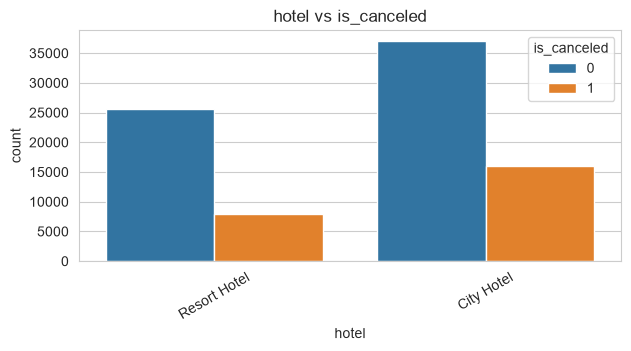

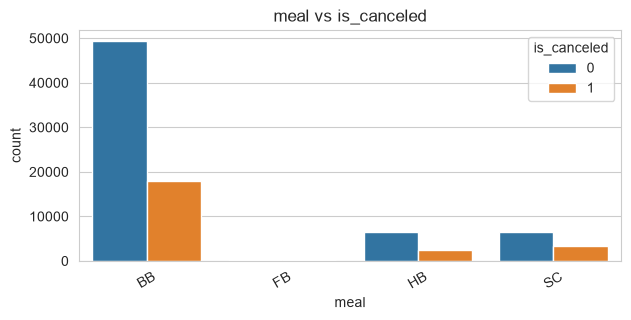

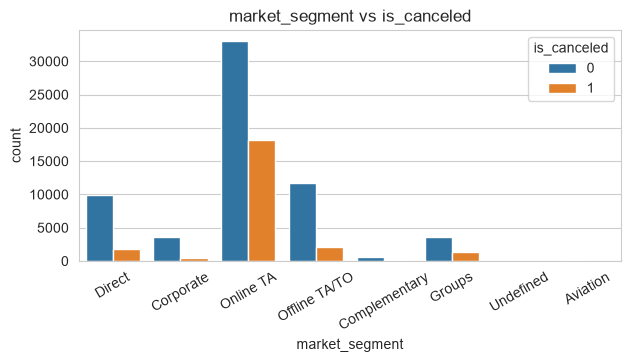

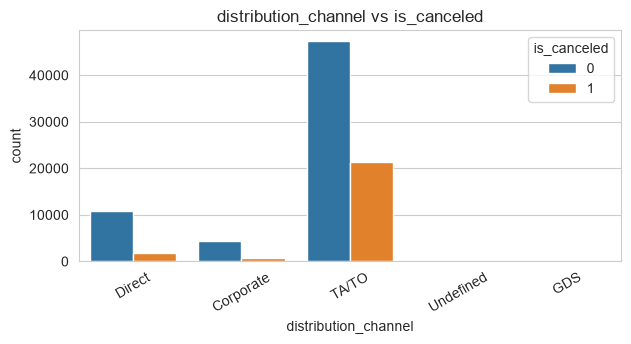

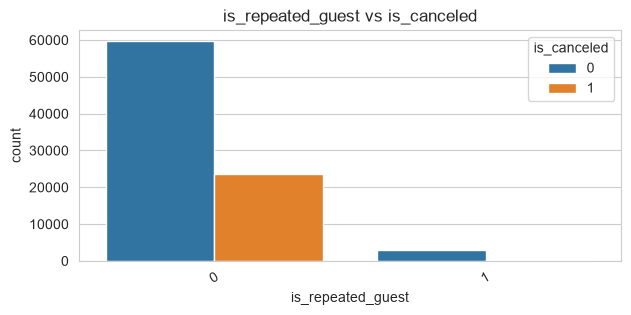

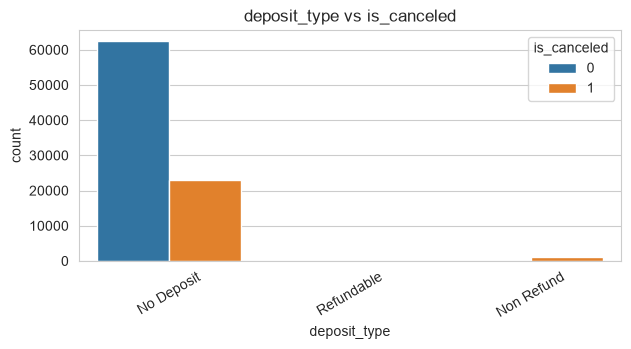

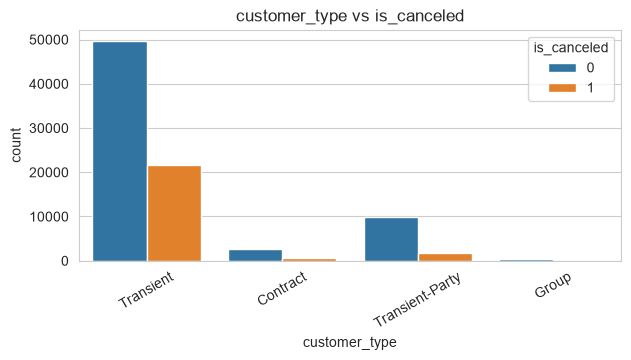

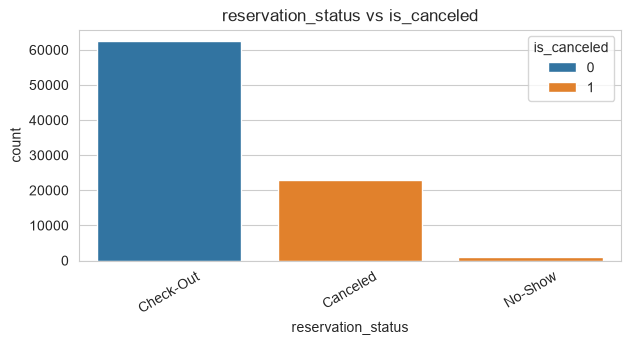

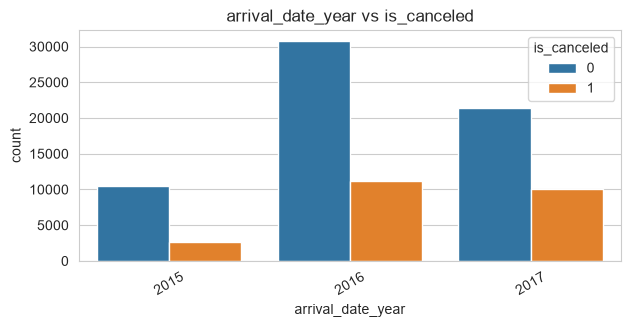

In [69]:
for col in ["hotel", "meal", "market_segment", "distribution_channel", "is_repeated_guest",
            "deposit_type", "customer_type", "reservation_status", "arrival_date_year"]:
    plt.figure(figsize=(7, 3))
    sns.countplot(x=df[col], hue=df["is_canceled"])
    plt.xticks(rotation=30)
    plt.title(col + " vs is_canceled")
    plt.show()

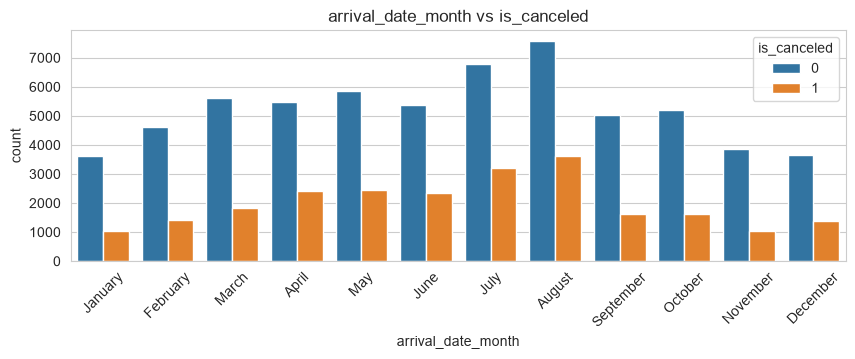

In [70]:
plt.figure(figsize=(10, 3))
sns.countplot(x=df["arrival_date_month"], hue=df["is_canceled"], order=month_order)
plt.xticks(rotation=45)
plt.title("arrival_date_month vs is_canceled")
plt.show()

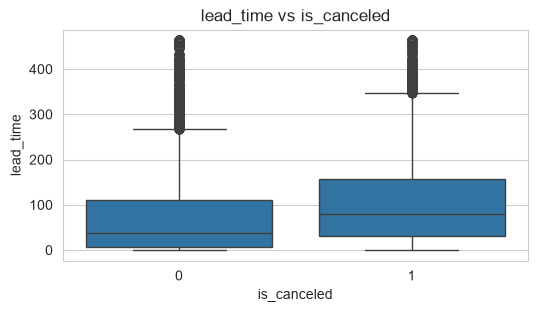

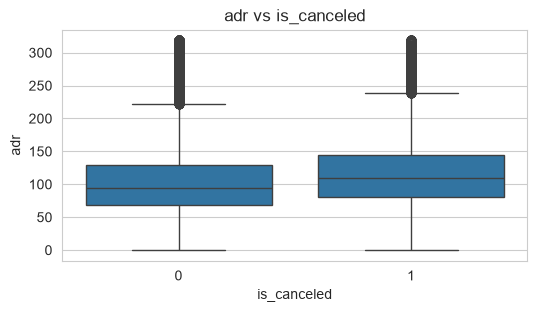

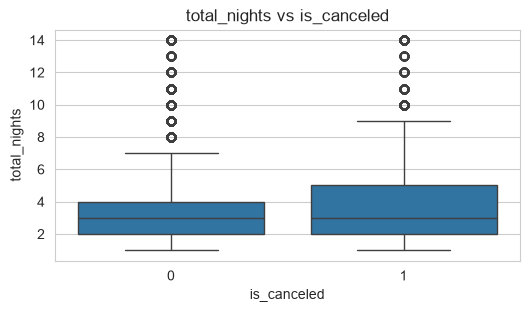

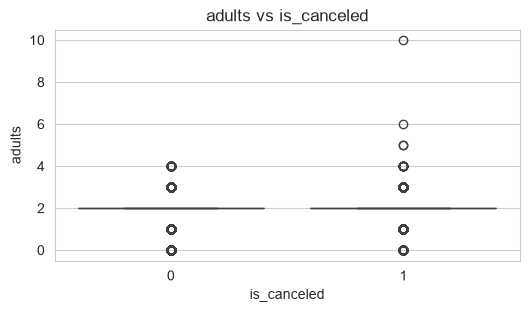

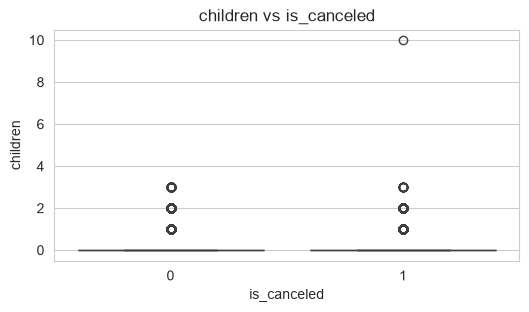

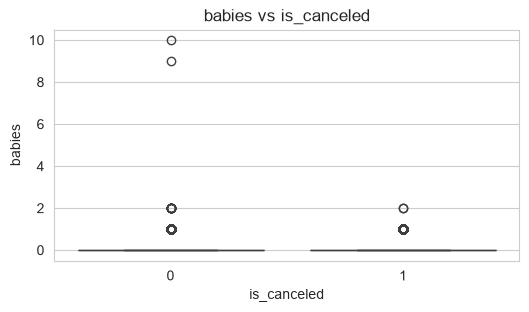

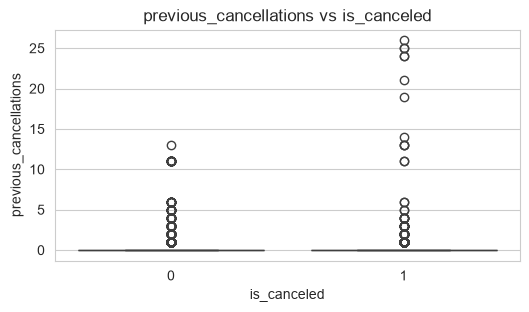

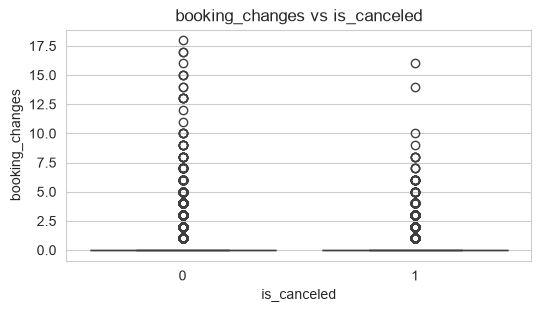

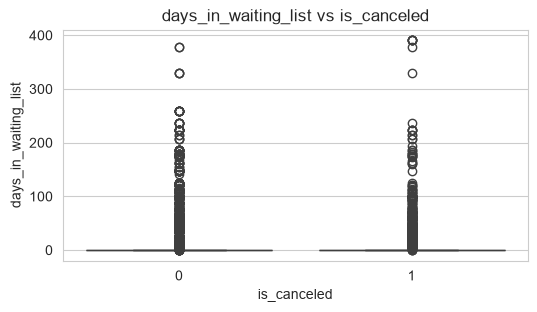

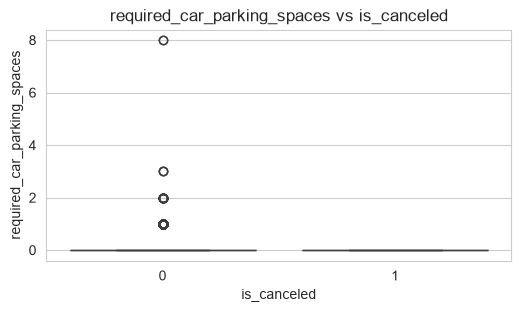

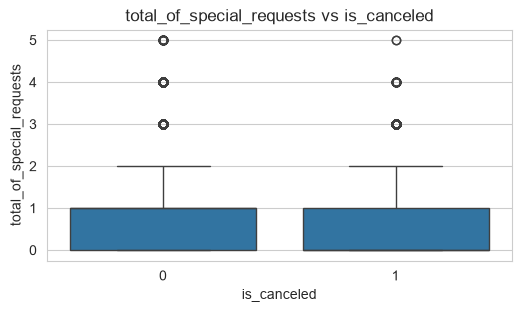

In [71]:
for col in ["lead_time", "adr", "total_nights", "adults", "children", "babies", "previous_cancellations",
            "booking_changes", "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df["is_canceled"], y=df[col])
    plt.title(col + " vs is_canceled")
    plt.show()

In [72]:

df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)
print(df.groupby("room_changed")["is_canceled"].mean())

room_changed
0    0.315902
1    0.048025
Name: is_canceled, dtype: float64


### Correlation

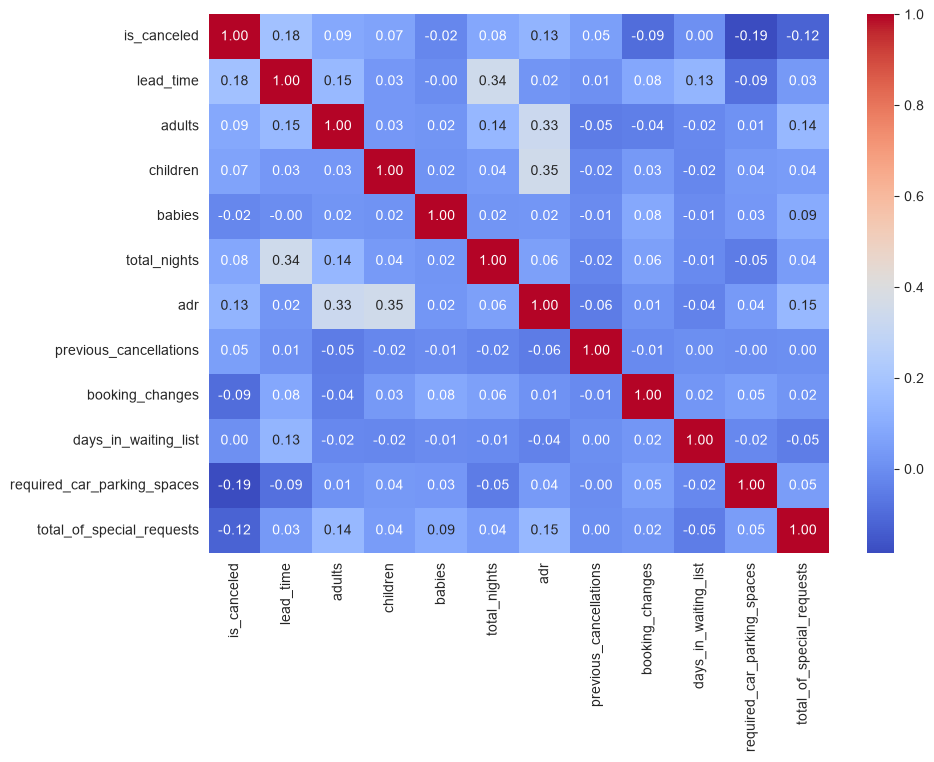

In [73]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[["is_canceled", "lead_time", "adults", "children", "babies", "total_nights", "adr",
                "previous_cancellations", "booking_changes", "days_in_waiting_list",
                "required_car_parking_spaces", "total_of_special_requests"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

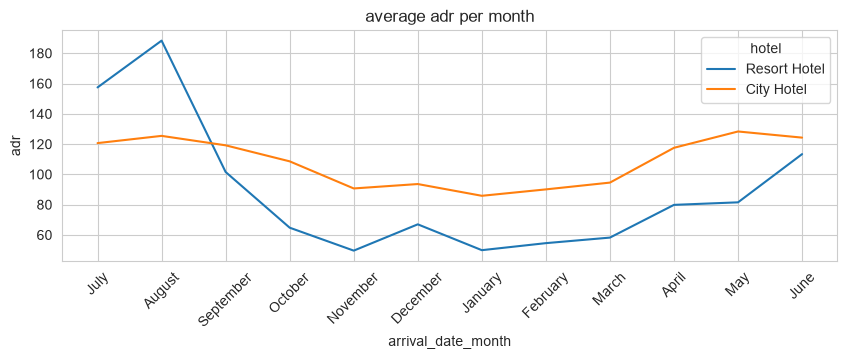

In [74]:
plt.figure(figsize=(10, 3))
sns.lineplot(data=df, x="arrival_date_month", y="adr", hue="hotel", errorbar=None, sort=False)
plt.xticks(rotation=45)
plt.title("average adr per month")
plt.show()

In [75]:
df.to_csv("hotel_booking_cleaned.csv", index=False)